# Interpolación matricial — Vandermonde y cambio de base

Construye M fila por nodo, columna por función base, resuelve M @ A = y y evalúa. La misma plantilla sirve para monomios, cosenos y Legendre. Splines se dejan fuera del C2.

**Fuente:** `05-interpolación, pp. 9–12` y notebook de clase original. Revisión de estudio con IA; usar en evaluación solo si el material asistido está autorizado.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Funciones para copiar
$M_{ij}=\phi_j(x_i)$ y $p(z)=\sum_j A_j\phi_j(z)$. Convención de argumentos: `phi(x,j)`, siempre en ese orden. Los coeficientes de monomios se guardan en orden ascendente.

In [2]:
def vandermonde(x):
    x = np.asarray(x,dtype=float)
    M = np.zeros((len(x),len(x)))
    for i in range(len(x)):
        for j in range(len(x)):
            M[i,j] = x[i]**j
    return M

def matriz_base(x, phi):
    x = np.asarray(x,dtype=float)
    M = np.zeros((len(x),len(x)))
    for i in range(len(x)):
        for j in range(len(x)):
            M[i,j] = phi(x[i],j)
    return M

def evaluar(z, A, phi):
    z = np.asarray(z)
    resultado = 0.0
    for j in range(len(A)):
        resultado = resultado + A[j]*phi(z,j)
    return resultado

## 2. Caso básico: polinomio en potencias
Modifica x e y. Si te dan N+1 nodos, la matriz es (N+1) × (N+1).

In [3]:
x = np.array([0.,1.,2.])
y = np.array([1.,2.,5.])
def phi(x,j):
    return x**j
M = vandermonde(x)
A = np.linalg.solve(M,y)
print('M:',M,'\nA (ascendente):',A)
print('p(0.5):',evaluar(0.5,A,phi))
assert np.allclose(M@A,y)
assert np.allclose(evaluar(x,A,phi),y)
assert np.allclose(A,[1,0,1])

M: [[1. 0. 0.]
 [1. 1. 1.]
 [1. 2. 4.]] 
A (ascendente): [1. 0. 1.]
p(0.5): 1.25


## 3. Caso de clase: base de cosenos
Se conservan los datos de `datos-01.txt`. Cambia `L` y la función base según el problema. No inviertas los argumentos de phi.

A: [ 2.6       -2.4472136 -1.2472136 -1.5527864 -0.3527864]
Condición: 4.614273206471733


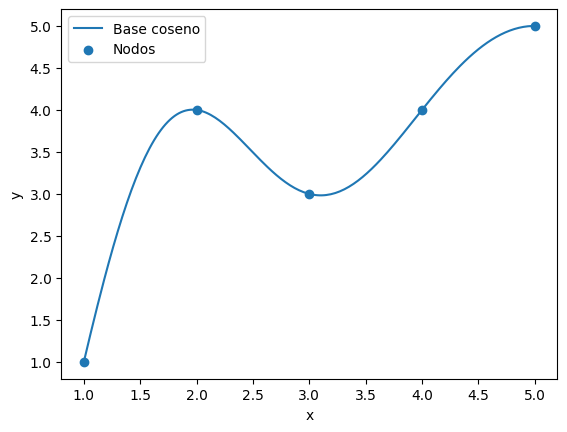

In [4]:
datos = np.genfromtxt('datos-01.txt')
x, y = datos[:,0], datos[:,1]
L = 5
def phi_cos(x,j):
    return np.cos(j*np.pi*x/L)
M = matriz_base(x,phi_cos)
A = np.linalg.solve(M,y)
print('A:',A)
print('Condición:',np.linalg.cond(M))
assert np.allclose(evaluar(x,A,phi_cos),y)
z = np.linspace(x.min(),x.max(),200)
plt.plot(z,evaluar(z,A,phi_cos),label='Base coseno')
plt.scatter(x,y,label='Nodos')
plt.xlabel('x'); plt.ylabel('y'); plt.legend(); plt.show()

## 4. Cambiar a base de Legendre
Ejemplo independiente sobre [-1,1]. `eval_legendre(j,x)` evalúa el polinomio P_j, pero no realiza la interpolación. Los coeficientes pertenecen a esta base, no a potencias de x.

In [5]:
from scipy.special import eval_legendre
def phi_leg(x,j):
    return eval_legendre(j,x)
x = np.array([-1.,-.3,.5,1.])
y = 1+x**2
M = matriz_base(x,phi_leg)
A = np.linalg.solve(M,y)
print('A en base Legendre:',A)
assert np.allclose(evaluar(x,A,phi_leg),y)
assert np.allclose(A,[4/3,0,2/3,0])

A en base Legendre: [ 1.33333333e+00 -6.90859661e-17  6.66666667e-01  6.90859661e-17]


## 5. Verificar errores y condicionamiento
Si conoces la función original, compara en una malla distinta de los nodos. Si solo tienes datos, no puedes medir el error real fuera de ellos. Ejemplo genérico.

In [6]:
def f(z):
    return np.exp(z)
for m in (4,8,12):
    x = np.linspace(-1,1,m)
    y = f(x)
    M = vandermonde(x)
    A = np.linalg.solve(M,y)
    z = np.linspace(-1,1,301)
    error = np.max(np.abs(f(z)-evaluar(z,A,phi)))
    print('nodos:',m,'condición:',np.linalg.cond(M),'error malla:',error)

nodos: 4 condición: 8.011561047197164 error malla: 0.009984523594588346
nodos: 8 condición: 535.3531175106015 error malla: 7.987940717768538e-07
nodos: 12 condición: 40754.8818416902 error malla: 1.326405651980167e-11


**Cuidado:** usa `solve`, no la inversa explícita. En base monomial los nodos distintos garantizan invertibilidad matemática, pero no buen condicionamiento. En bases generales debes verificar que la matriz no sea singular. `cond(M)` grande indica sensibilidad a errores; un residuo pequeño M@A−y no garantiza coeficientes precisos. Un error en malla es una estimación del máximo, no el máximo exacto.